# Are Action movies more successful for Disney?
Version 2 of my original analysis (`Disney_original.ipynb`), written up for the green-light committee.

**Question.** When choosing which films to green-light, should Disney favour Action projects because they earn more at the box office?

**Metric.** Domestic box-office gross, adjusted for inflation (from Disney's own gross file). Return on budget (gross / production budget) is the secondary metric.

**Data.** Disney's release list with domestic gross (579 titles, 1937-2016), joined to a public IMDb-style movies file (budget, IMDb score, lead star) and an actor popularity file. Only films that appear in both sources and have a budget make it into the analysis.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 140)
raw = pd.read_csv(ROOT / 'data/raw/final_df.csv')
disney_all = pd.read_csv(ROOT / 'data/raw/disney_movies_total_gross.csv')
print('Disney release list:', disney_all.shape, '| merged Disney x IMDb file:', raw.shape)
print('Null cells in merged file:', int(raw.isna().sum().sum()))
print('Null cells in Disney list by column:', disney_all.isna().sum()[lambda s: s > 0].to_dict())

Disney release list: (579, 6) | merged Disney x IMDb file: (156, 23)
Null cells in merged file: 0
Null cells in Disney list by column: {'genre': 17, 'mpaa_rating': 56}


## 1. Data cleaning
The merged file has no nulls, but the two sources were joined on title alone. Several Disney classics got matched to a *different* film with the same name (usually a later remake) and picked up the wrong budget. The rule I used: drop a row if the Disney release year and the IMDb year are more than one year apart.

In [2]:
df = raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed')]).copy()
df['release_year'] = pd.to_datetime(df['release_date'], format='%d/%m/%Y').dt.year
bad = (df['release_year'] - df['year']).abs() > 1
display(df.loc[bad, ['name', 'release_year', 'year', 'budget', 'total_gross']].rename(columns={'year': 'imdb_year'}))
df = df.loc[~bad].drop_duplicates(subset=['name', 'release_year'])
df = df[(df.budget > 0) & (df.total_gross > 0)].copy()
print(f'Rows: {len(raw)} raw -> {len(df)} clean ({bad.sum()} title-match errors dropped, 0 nulls, 0 non-positive budgets)')

,name,release_year,imdb_year,budget,total_gross
31,Beauty and the Beast,1991,2017,160000000,218951625
38,Aladdin,1992,2019,183000000,217350219
45,The Three Musketeers,1993,2011,75000000,53661805
55,The Avengers,2012,1998,60000000,623279547
58,Bad Company,1995,2002,70000000,3523909
62,Man of the House,1995,2005,40000000,40029009
76,Hercules,1997,2014,100000000,99112101
100,The Rookie,2002,1990,10000000,75600072


Rows: 156 raw -> 148 clean (8 title-match errors dropped, 0 nulls, 0 non-positive budgets)


In [3]:
# Derived fields. Budget is scaled by the same inflation factor Disney applied to gross.
df['inflation_factor'] = df.inflation_adjusted_gross / df.total_gross
df['inflation_budget'] = df.budget * df.inflation_factor
df['roi_multiple'] = df.total_gross / df.budget
df['log_gross'] = np.log(df.inflation_adjusted_gross)
df['log_budget'] = np.log(df.inflation_budget)
df['is_action'] = (df.genre_x == 'Action').astype(int)        # Disney's own genre label (primary)
df['is_action_imdb'] = (df.genre_y == 'Action').astype(int)   # IMDb label (sensitivity check)
df['is_marvel'] = df.company.isin(['Marvel Studios', 'Marvel Entertainment']).astype(int)
df = df.rename(columns={'score': 'imdb_score', 'star_rating': 'star_power'})

# Cross-check against the shared cleaning code used by SQL, Excel and the dashboard
from common import clean_final_df
shared = clean_final_df()
assert len(shared) == len(df) and set(shared.title) == set(df.name)
print(f'Matches src/common.py cleaning: {len(shared)} films, {df.release_year.min()} to {df.release_year.max()}')

Matches src/common.py cleaning: 148 films, 1984 to 2016


## 2. Exploratory analysis

In [4]:
summary = (df.groupby('genre_x')
             .agg(films=('name', 'count'),
                  avg_gross_musd=('inflation_adjusted_gross', lambda s: s.mean() / 1e6),
                  median_gross_musd=('inflation_adjusted_gross', lambda s: s.median() / 1e6),
                  avg_budget_musd=('inflation_budget', lambda s: s.mean() / 1e6),
                  pooled_roi=('inflation_adjusted_gross', 'sum'))
             .sort_values('avg_gross_musd', ascending=False))
summary['pooled_roi'] = summary.pooled_roi / df.groupby('genre_x').inflation_budget.sum()
summary

,films,avg_gross_musd,median_gross_musd,avg_budget_musd,pooled_roi
genre_x,,,,,
Action,20,205.786,172.342,145.792,1.412
Adventure,33,195.960,190.989,144.876,1.353
Thriller/Suspense,11,141.240,73.794,72.660,1.944
Romantic Comedy,10,122.039,96.408,53.591,2.277
Comedy,43,95.583,85.758,54.301,1.760
Western,3,90.994,91.341,148.234,0.614
Drama,27,66.392,50.840,51.258,1.295
Horror,1,19.452,19.452,31.892,0.610


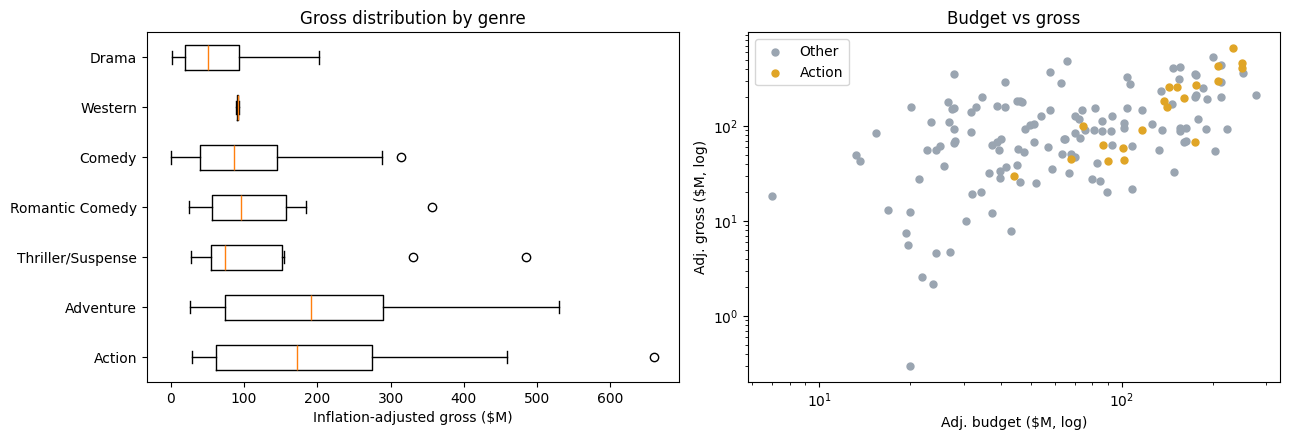

Action films cost 1.81x as much on average ($146M vs $81M).


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = summary.index[summary.films >= 3]
axes[0].boxplot([df.loc[df.genre_x == g, 'inflation_adjusted_gross'] / 1e6 for g in order], tick_labels=order, vert=False)
axes[0].set_xlabel('Inflation-adjusted gross ($M)'); axes[0].set_title('Gross distribution by genre')
for flag, col, lab in [(0, '#9aa5b1', 'Other'), (1, '#e0a526', 'Action')]:
    s = df[df.is_action == flag]
    axes[1].scatter(s.inflation_budget / 1e6, s.inflation_adjusted_gross / 1e6, c=col, label=lab, s=25)
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].legend()
axes[1].set_xlabel('Adj. budget ($M, log)'); axes[1].set_ylabel('Adj. gross ($M, log)'); axes[1].set_title('Budget vs gross')
plt.tight_layout(); plt.show()
act, non = df[df.is_action == 1], df[df.is_action == 0]
print(f'Action films cost {act.inflation_budget.mean() / non.inflation_budget.mean():.2f}x as much on average '
      f'(${act.inflation_budget.mean()/1e6:,.0f}M vs ${non.inflation_budget.mean()/1e6:,.0f}M).')

**Read-out.** Action has the highest *average* gross, but Action films also get much bigger budgets, and gross climbs steeply with budget. So the raw averages mix up two things, the genre and the money behind it. The tests below pull them apart.

## 3. Welch t-test: Action vs non-Action gross (no controls)
I used Welch's version because it doesn't assume equal variances. The two groups differ a lot in size (20 vs 128) and in spread.

In [6]:
t = stats.ttest_ind(act.inflation_adjusted_gross, non.inflation_adjusted_gross, equal_var=False)
t_log = stats.ttest_ind(act.log_gross, non.log_gross, equal_var=False)
mw = stats.mannwhitneyu(act.inflation_adjusted_gross, non.inflation_adjusted_gross)
t_roi = stats.ttest_ind(act.roi_multiple, non.roi_multiple, equal_var=False)
pd.DataFrame({
    'Action': [len(act), act.inflation_adjusted_gross.mean() / 1e6, act.inflation_adjusted_gross.median() / 1e6, act.roi_multiple.mean()],
    'Non-Action': [len(non), non.inflation_adjusted_gross.mean() / 1e6, non.inflation_adjusted_gross.median() / 1e6, non.roi_multiple.mean()]},
    index=['films', 'mean gross $M', 'median gross $M', 'mean ROI']).join(
    pd.Series({'mean gross $M': t.pvalue, 'median gross $M': mw.pvalue, 'mean ROI': t_roi.pvalue}, name='p-value'))

,Action,Non-Action,p-value
films,20.000,128.000,NaN
mean gross $M,205.786,120.592,0.045
median gross $M,172.342,88.755,0.031
mean ROI,1.228,1.923,0.003


In [7]:
print(f'Welch t on gross: t={t.statistic:.2f}, p={t.pvalue:.3f} | on log gross: p={t_log.pvalue:.3f} | Mann-Whitney p={mw.pvalue:.3f}')
print(f'Welch t on ROI: p={t_roi.pvalue:.4f} (Action mean ROI {act.roi_multiple.mean():.2f} vs {non.roi_multiple.mean():.2f})')

Welch t on gross: t=2.12, p=0.045 | on log gross: p=0.009 | Mann-Whitney p=0.031
Welch t on ROI: p=0.0027 (Action mean ROI 1.23 vs 1.92)


**What this says.** Without controls, Action films gross more, and the gap is significant at the 5% level (p ≈ 0.045). On *return per budget dollar*, though, Action does worse, and that gap is significant too. Next question: does the gross advantage hold up once budget is fixed?

## 4. Regression: does Action matter once budget, quality and star power are held constant?
Model M2: `log(gross) = b0 + b1·Action + b2·log(budget) + b3·star_power + b4·IMDb score`, fit by OLS with HC3 (heteroskedasticity-consistent) standard errors. Taking logs turns the coefficients into percentage effects and keeps a few blockbusters from dominating the fit.

In [8]:
MAIN = 'log_gross ~ is_action + log_budget + star_power + imdb_score'
m1 = smf.ols('log_gross ~ is_action', df).fit(cov_type='HC3')
m2 = smf.ols(MAIN, df).fit(cov_type='HC3')
summ = m2.summary()
print(summ.tables[0]); print(summ.tables[1])  # covariance type (HC3) is listed in the top table

                            OLS Regression Results                            
Dep. Variable:              log_gross   R-squared:                       0.395
Model:                            OLS   Adj. R-squared:                  0.378
Method:                 Least Squares   F-statistic:                     14.17
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           9.18e-10
Time:                        14:32:54   Log-Likelihood:                -198.17
No. Observations:                 148   AIC:                             406.3
Df Residuals:                     143   BIC:                             421.3
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2422      2.398      0.518      0.6

In [9]:
def effect(m, term, label):
    lo, hi = m.conf_int().loc[term]
    return {'model': label, 'n': int(m.nobs), 'R2': m.rsquared, 'Action effect %': 100 * (np.exp(m.params[term]) - 1),
            'CI low %': 100 * (np.exp(lo) - 1), 'CI high %': 100 * (np.exp(hi) - 1), 'p-value': m.pvalues[term]}

m3 = smf.ols(MAIN, df[df.is_marvel == 0]).fit(cov_type='HC3')
m4 = smf.ols(MAIN.replace('is_action', 'is_action_imdb'), df).fit(cov_type='HC3')
m5 = smf.ols(MAIN + ' + is_action:star_power + is_action:imdb_score', df).fit(cov_type='HC3')
pd.DataFrame([effect(m1, 'is_action', 'M1 Action only'), effect(m2, 'is_action', 'M2 with controls'),
              effect(m3, 'is_action', 'M3 controls, Marvel excluded'),
              effect(m4, 'is_action_imdb', 'M4 controls, IMDb genre label')]).set_index('model')

,n,R2,Action effect %,CI low %,CI high %,p-value
model,,,,,,
M1 Action only,148,0.036,92.826,20.286,209.115,0.006
M2 with controls,148,0.395,-0.352,-21.936,27.199,0.977
"M3 controls, Marvel excluded",141,0.341,-8.835,-30.396,19.405,0.502
"M4 controls, IMDb genre label",148,0.397,-13.269,-32.909,12.120,0.277


In [10]:
b = m2.params
print(f"Budget: +10% budget -> {100*(1.1**b['log_budget']-1):.1f}% more gross (elasticity {b['log_budget']:.2f}, p={m2.pvalues['log_budget']:.1e})")
print(f"IMDb score: +1 point -> {100*(np.exp(b['imdb_score'])-1):.0f}% more gross (p={m2.pvalues['imdb_score']:.4f})")
print(f"Star power: +100 rating points -> {100*(np.exp(100*b['star_power'])-1):.1f}% (p={m2.pvalues['star_power']:.2f}, not significant)")
print(f"Action: {100*(np.exp(b['is_action'])-1):+.1f}% (p={m2.pvalues['is_action']:.2f}, not significant)")
print('Interaction p-values (M5):', m5.pvalues[['is_action:star_power', 'is_action:imdb_score']].round(3).to_dict())

Budget: +10% budget -> 7.8% more gross (elasticity 0.79, p=9.6e-12)
IMDb score: +1 point -> 47% more gross (p=0.0009)
Star power: +100 rating points -> 2.4% (p=0.40, not significant)
Action: -0.4% (p=0.98, not significant)
Interaction p-values (M5): {'is_action:star_power': 0.89, 'is_action:imdb_score': 0.188}


### Reading the coefficients
- Action: with budget, IMDb score and star power in the model, Action films earn about the same as comparable non-Action films. The estimate is near zero and not significant, and the 95% interval runs from roughly -22% to +27%. The raw Action advantage comes from bigger budgets.
- Budget is the strongest driver. Each 1% of extra budget goes with about 0.79% more gross. That's below 1, so gross grows more slowly than spend. Bigger bets earn more dollars, just not proportionally more.
- Each extra IMDb point is associated with roughly 47% more gross, and that one is significant. Audience reception matters more than genre.
- Star power has no measurable effect after controls.
- Sensitivity checks: the Action result stays non-significant without Marvel, with IMDb's genre label instead of Disney's, and when Action can interact with score or star power.

## 5. Limitations
- Small sample. 148 films, only 20 of them Action, so the Action confidence interval is wide and a modest real effect can't be ruled out.
- Selection. Only 148 of 579 Disney titles have budget data and a correct match. Older catalogue titles and small releases drop out.
- Budget is a confounder. Action and budget are correlated, and the model separates them statistically but can't prove causation. Budget itself is set with expected demand in mind.
- Marvel. The sample has seven Marvel films (five labelled Action by Disney), including four of the eight highest grossers. They drive much of the raw Action average.
- Metric scope. Gross is domestic only and budgets exclude marketing. International, streaming and merchandising revenue aren't included.
- Labels. Disney and IMDb disagree on genre for many films (Disney calls 20 films Action, IMDb more than twice that), so "Action" is a fuzzy category.

In [11]:
# Consistency check with the pipeline results used by README, Excel and the memo
res = json.loads((ROOT / 'data/processed/model_results.json').read_text())
assert abs(res['m2_coef']['is_action'] - m2.params['is_action']) < 1e-9
assert abs(res['welch_p'] - t.pvalue) < 1e-12 and res['m2_n'] == int(m2.nobs)
print('Notebook numbers match data/processed/model_results.json')

Notebook numbers match data/processed/model_results.json


## 6. Conclusion for the green-light committee
Action on its own isn't a reason to green-light a film. Action films out-gross other genres because Disney spends more on them. At comparable budget, quality and star power, the genre adds no detectable box-office premium, and its mean return per budget dollar is lower. Budget-adjusted expected return and quality signals should drive the decision, and Marvel-type franchises should be judged as franchises, not as a genre.